# Genesis Mission Funding and Collaboration Dashboard

This dashboard summarizes BASELINE and UFR funding by Genesis Mission Challenge, program office contribution, and collaboration opportunity. Validation and confidence details are retained as traceability appendix material in the exported static HTML report.


In [1]:
from pathlib import Path
from html import escape
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display


def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing pyproject.toml")


PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from programming_ontology import paths
from programming_ontology.asksage_classifier import (
    default_credentials_path,
    resolve_asksage_openai_base_url,
)
from programming_ontology.classify_programming import run_classification_pipeline

paths.ensure_output_dirs()

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 220)
plt.style.use("default")


def format_money(value):
    value = 0 if pd.isna(value) else float(value)
    sign = "-" if value < 0 else ""
    value = abs(value)
    if value >= 1_000_000_000:
        return f"{sign}${value / 1_000_000_000:,.2f}B"
    if value >= 1_000_000:
        return f"{sign}${value / 1_000_000:,.1f}M"
    return f"{sign}${value:,.0f}"


def bool_env(name, default=False):
    raw = os.environ.get(name, "").strip().casefold()
    if not raw:
        return default
    return raw in {"1", "true", "yes", "y", "on"}


def optional_int_env(name):
    raw = os.environ.get(name, "").strip()
    return int(raw) if raw else None


In [2]:
REQUIRED_ARTIFACT_PATHS = {
    "row-level classifications": paths.PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH,
    "reviewed classifications": paths.REVIEWED_PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH,
    "office claim validation": paths.OFFICE_CLAIM_VALIDATION_PATH,
    "challenge coverage summary": paths.CHALLENGE_COVERAGE_SUMMARY_PATH,
    "office challenge evidence": paths.OFFICE_CHALLENGE_EVIDENCE_PATH,
    "WBS challenge summary": paths.WBS_CHALLENGE_SUMMARY_PATH,
    "classified ontology graph": paths.CLASSIFIED_ONTOLOGY_GRAPH_PATH,
}


def artifact_ready(path):
    return path.exists() and path.stat().st_size > 0


missing_artifacts = [
    name for name, path in REQUIRED_ARTIFACT_PATHS.items() if not artifact_ready(path)
]
REFRESH_ARTIFACTS_WITH_ASKSAGE = bool_env("REFRESH_ARTIFACTS_WITH_ASKSAGE", default=False)
AUTO_REFRESH_MISSING_ARTIFACTS = bool_env("AUTO_REFRESH_MISSING_ARTIFACTS", default=True)
ASKSAGE_TOP_K = int(os.environ.get("ASKSAGE_TOP_K", "5"))
ASKSAGE_LIMIT = optional_int_env("ASKSAGE_LIMIT")
ASKSAGE_REASONING_EFFORT = os.environ.get("ASKSAGE_REASONING_EFFORT", "medium").strip()
ASKSAGE_CREDENTIALS_PATH = default_credentials_path()
ASKSAGE_MODEL = os.environ.get("ASKSAGE_MODEL", "").strip() or None
ASKSAGE_OPENAI_BASE_URL = resolve_asksage_openai_base_url(credentials_path=ASKSAGE_CREDENTIALS_PATH)

should_refresh = REFRESH_ARTIFACTS_WITH_ASKSAGE or (
    AUTO_REFRESH_MISSING_ARTIFACTS and bool(missing_artifacts)
)

print(f"Using Ask Sage credentials file: {ASKSAGE_CREDENTIALS_PATH}")
print(f"Resolved OpenAI SDK base URL: {ASKSAGE_OPENAI_BASE_URL}")

if should_refresh:
    if missing_artifacts:
        display(Markdown("Refreshing because required artifacts are missing: " + ", ".join(missing_artifacts)))
    else:
        display(Markdown("Refreshing artifacts with Ask Sage because `REFRESH_ARTIFACTS_WITH_ASKSAGE` is enabled."))
    refresh_outputs = run_classification_pipeline(
        classifier="asksage",
        model=ASKSAGE_MODEL,
        top_k=ASKSAGE_TOP_K,
        reasoning_effort=ASKSAGE_REASONING_EFFORT,
        limit=ASKSAGE_LIMIT,
        resume_cache=True,
        audit_cache_path=paths.ASKSAGE_CLASSIFICATION_AUDIT_PATH,
        write_outputs=True,
    )
    display(Markdown(f"Refreshed **{len(refresh_outputs['classifications']):,}** rows with Ask Sage."))
else:
    if missing_artifacts:
        raise FileNotFoundError(
            "Required dashboard artifacts are missing and auto-refresh is disabled: "
            + ", ".join(missing_artifacts)
        )
    display(Markdown("Using existing processed artifacts. Set `REFRESH_ARTIFACTS_WITH_ASKSAGE=1` to regenerate them with Ask Sage."))


Using Ask Sage credentials file: C:\Users\Cameron.Webster\Python\ProgrammingOntology\credentials.json
Resolved OpenAI SDK base URL: https://api.nnsa.asksage.ai/server/openai/v1


Using existing processed artifacts. Set `REFRESH_ARTIFACTS_WITH_ASKSAGE=1` to regenerate them with Ask Sage.

In [3]:
classifications = pd.read_csv(paths.PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH)
reviewed_classifications = pd.read_csv(paths.REVIEWED_PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH)
office_claim_validation = pd.read_csv(paths.OFFICE_CLAIM_VALIDATION_PATH)
challenge_coverage = pd.read_csv(paths.CHALLENGE_COVERAGE_SUMMARY_PATH)
office_challenge_evidence = pd.read_csv(paths.OFFICE_CHALLENGE_EVIDENCE_PATH)
wbs_challenge_summary = pd.read_csv(paths.WBS_CHALLENGE_SUMMARY_PATH)

for frame in [classifications, reviewed_classifications, office_claim_validation, challenge_coverage, office_challenge_evidence, wbs_challenge_summary]:
    if "five_year_total" in frame.columns:
        frame["five_year_total"] = pd.to_numeric(frame["five_year_total"], errors="coerce").fillna(0.0)

display(Markdown(f"""
## Loaded Artifacts

- Row-level classifications: **{len(classifications):,}**
- Reviewed evidence rows: **{len(reviewed_classifications):,}**
- Office-challenge claims: **{len(office_claim_validation):,}**
- Positive BASELINE/UFR evidence: **{format_money(office_challenge_evidence['five_year_total'].sum())}**
"""))


## Loaded Artifacts

- Row-level classifications: **61**
- Reviewed evidence rows: **61**
- Office-challenge claims: **32**
- Positive BASELINE/UFR evidence: **$4.98B**


,claim_count,five_year_total,five_year_total_display
validation_status,,,
validated,8,$2.90B,$2.90B
needs_review,2,$1.02B,$1.02B
unfunded,22,$0,$0


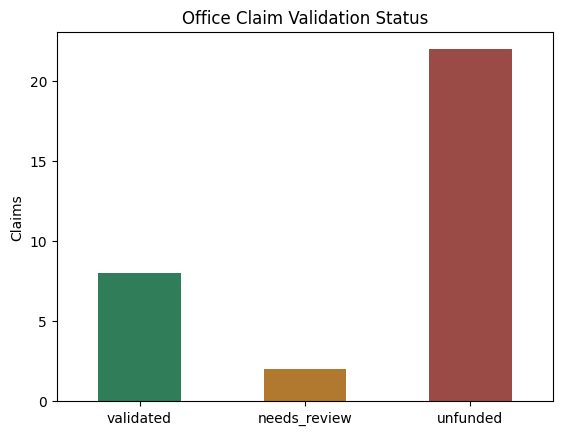

In [4]:
status_counts = office_claim_validation["validation_status"].value_counts().reindex(["validated", "needs_review", "unfunded"], fill_value=0)
status_funding = office_claim_validation.groupby("validation_status")["five_year_total"].sum().reindex(["validated", "needs_review", "unfunded"], fill_value=0.0)

executive_summary = pd.DataFrame(
    {
        "claim_count": status_counts,
        "five_year_total": status_funding.map(format_money),
        "five_year_total_display": status_funding.map(format_money),
    }
)
display(executive_summary)

ax = status_counts.plot(kind="bar", color=["#2f7d59", "#b1792f", "#9a4b45"], rot=0)
ax.set_title("Office Claim Validation Status")
ax.set_xlabel("")
ax.set_ylabel("Claims")
plt.show()

## Lead Office Accountability

These tables and visuals focus only on Genesis Mission Challenge claims where a program office is identified as the lead. The execution check compares each lead claim against actual BASELINE and UFR programming rows where that same office is funding work classified to the claimed challenge.


### Which offices claim lead responsibility?

,challenge_name,lead_program_office,execution_signal,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,high_confidence_count,medium_confidence_count,low_confidence_count,review_flag_count,evidence_wbs_names
0,Integrating Design and Production Operations for Nuclear Deterrence,NA12,"Executing, review evidence",needs_review,2,1,$483.4M,0,0,2,0,Multi-Weapon Systems (formerly MTP)
1,Safeguarding Nuclear Materials from Proliferation Threats,NA20,"Executing, review evidence",needs_review,4,3,$535.0M,3,1,0,4,Civil Nuclear Cooperation & Engagement; Export Control; PD
4,Accelerating Business and Management Processes for National Security Missions,NA-MB,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
6,Accelerating Nuclear Enterprise Acquisition,NA-PAS,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
5,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",NA19,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
3,(CUI) Preventing AI-Induced Nuclear Proliferation,NA80,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
23,Strengthening Deterrence Through Attribution of Nuclear and Radiological Signatures,NA80,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
21,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NA90,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
28,Harnessing America’s Historic Nuclear Data and Research,NA11,Executing with clear evidence,validated,5,3,$1.04B,2,3,0,3,Archiving & Support; Artificial Intelligence for Nuclear Security (AI4NS); Computational Systems & Software Environment
29,Increasing Experimental Capacity at Nuclear Research Facilities,NA11,Executing with clear evidence,validated,4,4,$79.5M,1,3,0,2,"Delivery Environments (formerly WSEAT); Facility Operations (formerly also Target Production); ICF Diagnostics & Instrumentation (formerly Diagnostics, Cryogenics & Experimental Support); Secondary Assessment Technol..."


### Lead office by Genesis Mission Challenge

lead_program_office,NA-MB,NA-PAS,NA11,NA12,NA19,NA20,NA80,NA90
challenge_name,,,,,,,,
(CUI) Preventing AI-Induced Nuclear Proliferation,,,,,,,unfunded,
Accelerating Business and Management Processes for National Security Missions,unfunded,,,,,,,
"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",,,,,unfunded,,,
Accelerating Nuclear Enterprise Acquisition,,unfunded,,,,,,
"Accelerating Nuclear Threat Assessment, Preparedness, and Response",,,,,,,validated,
Harnessing America’s Historic Nuclear Data and Research,,,validated,,,,,
Increasing Experimental Capacity at Nuclear Research Facilities,,,validated,,,,,
Integrating Design and Production Operations for Nuclear Deterrence,,,,needs_review,,,,
Safeguarding Nuclear Materials from Proliferation Threats,,,,,,needs_review,,


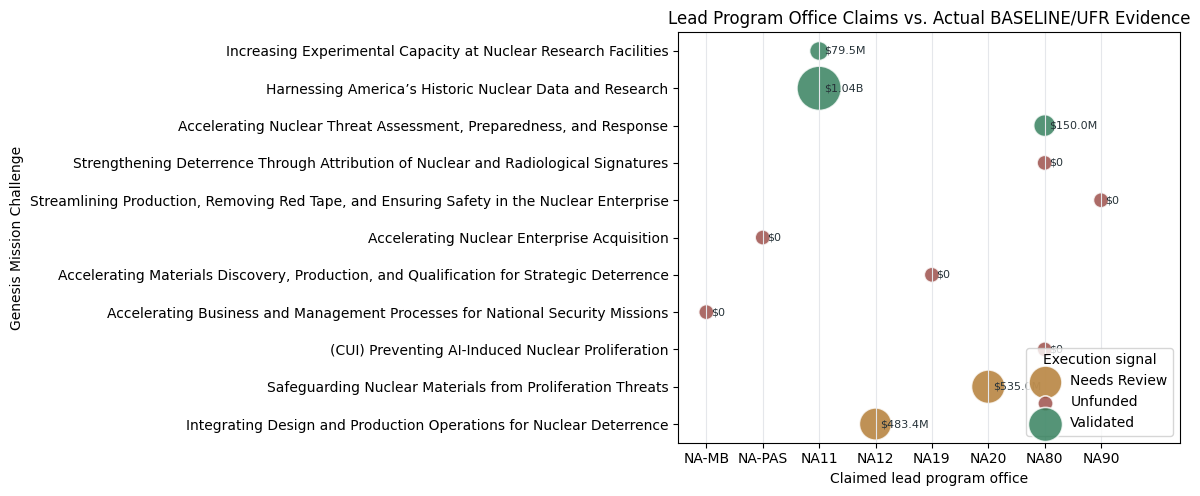

In [5]:
LEAD_STATUS_COLORS = {
    "validated": "#2f7d59",
    "needs_review": "#b1792f",
    "unfunded": "#9a4b45",
}
FUNDING_LEVEL_COLORS = {"BASELINE": "#4c78a8", "UFR": "#f58518"}
FY_COLUMNS = ["fy2028", "fy2029", "fy2030", "fy2031", "fy2032"]

lead_claims = office_claim_validation.loc[
    office_claim_validation["claim_role"].astype(str).str.casefold().eq("lead")
].copy()
lead_claims = lead_claims.rename(columns={"claimed_office": "lead_program_office"})
lead_claims["execution_signal"] = lead_claims["validation_status"].map(
    {
        "validated": "Executing with clear evidence",
        "needs_review": "Executing, review evidence",
        "unfunded": "No BASELINE/UFR evidence found",
    }
).fillna("Unknown")
lead_claims["five_year_total_display"] = lead_claims["five_year_total"].map(format_money)
lead_claims_display = lead_claims[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "evidence_row_count",
        "evidence_wbs_count",
        "five_year_total_display",
        "high_confidence_count",
        "medium_confidence_count",
        "low_confidence_count",
        "review_flag_count",
        "evidence_wbs_names",
    ]
].sort_values(["validation_status", "lead_program_office", "challenge_name"])

display(Markdown("### Which offices claim lead responsibility?"))
display(lead_claims_display)

lead_claim_matrix = lead_claims.pivot_table(
    index="challenge_name",
    columns="lead_program_office",
    values="validation_status",
    aggfunc=lambda values: "; ".join(sorted(set(values))),
    fill_value="",
)
display(Markdown("### Lead office by Genesis Mission Challenge"))
display(lead_claim_matrix)

if not lead_claims.empty:
    challenges_order = lead_claims["challenge_name"].drop_duplicates().tolist()
    offices_order = sorted(lead_claims["lead_program_office"].drop_duplicates())
    x_positions = {office: index for index, office in enumerate(offices_order)}
    y_positions = {challenge: index for index, challenge in enumerate(challenges_order)}
    max_amount = max(float(lead_claims["five_year_total"].max()), 1.0)

    fig, ax = plt.subplots(figsize=(12, max(4.5, 0.46 * len(challenges_order))))
    for status, status_rows in lead_claims.groupby("validation_status"):
        amounts = status_rows["five_year_total"].astype(float).clip(lower=0.0)
        sizes = 120 + (amounts / max_amount) * 900
        ax.scatter(
            status_rows["lead_program_office"].map(x_positions),
            status_rows["challenge_name"].map(y_positions),
            s=sizes,
            color=LEAD_STATUS_COLORS.get(status, "#6b7280"),
            alpha=0.82,
            edgecolor="white",
            linewidth=1.2,
            label=status.replace("_", " ").title(),
        )
    for _, row in lead_claims.iterrows():
        ax.text(
            x_positions[row["lead_program_office"]] + 0.08,
            y_positions[row["challenge_name"]],
            format_money(row["five_year_total"]),
            va="center",
            fontsize=8,
            color="#263238",
        )
    ax.set_xticks(range(len(offices_order)))
    ax.set_xticklabels(offices_order)
    ax.set_yticks(range(len(challenges_order)))
    ax.set_yticklabels(challenges_order)
    ax.set_xlim(-0.5, max(len(offices_order) - 0.5, 0.5) + 0.9)
    ax.set_title("Lead Program Office Claims vs. Actual BASELINE/UFR Evidence")
    ax.set_xlabel("Claimed lead program office")
    ax.set_ylabel("Genesis Mission Challenge")
    ax.grid(axis="x", color="#e5e7eb", linewidth=0.8)
    ax.legend(title="Execution signal", loc="lower right")
    plt.tight_layout()
    plt.show()


### Lead office BASELINE/UFR funding by claimed mission

,challenge_name,lead_program_office,execution_signal,validation_status,baseline_display,ufr_display,lead_programmed_total_display,baseline_project_rows,ufr_project_rows,evidence_wbs_count,review_flag_count
0,Integrating Design and Production Operations for Nuclear Deterrence,NA12,"Executing, review evidence",needs_review,$0,$483.4M,$483.4M,0.0,2.0,1,0
1,Safeguarding Nuclear Materials from Proliferation Threats,NA20,"Executing, review evidence",needs_review,$165.0M,$370.0M,$535.0M,1.0,3.0,3,4
3,Accelerating Business and Management Processes for National Security Missions,NA-MB,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
5,Accelerating Nuclear Enterprise Acquisition,NA-PAS,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
4,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",NA19,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
2,(CUI) Preventing AI-Induced Nuclear Proliferation,NA80,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
7,Strengthening Deterrence Through Attribution of Nuclear and Radiological Signatures,NA80,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
6,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NA90,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
9,Harnessing America’s Historic Nuclear Data and Research,NA11,Executing with clear evidence,validated,$77.5M,$958.2M,$1.04B,1.0,4.0,3,3
10,Increasing Experimental Capacity at Nuclear Research Facilities,NA11,Executing with clear evidence,validated,$79.5M,$0,$79.5M,4.0,0.0,4,2


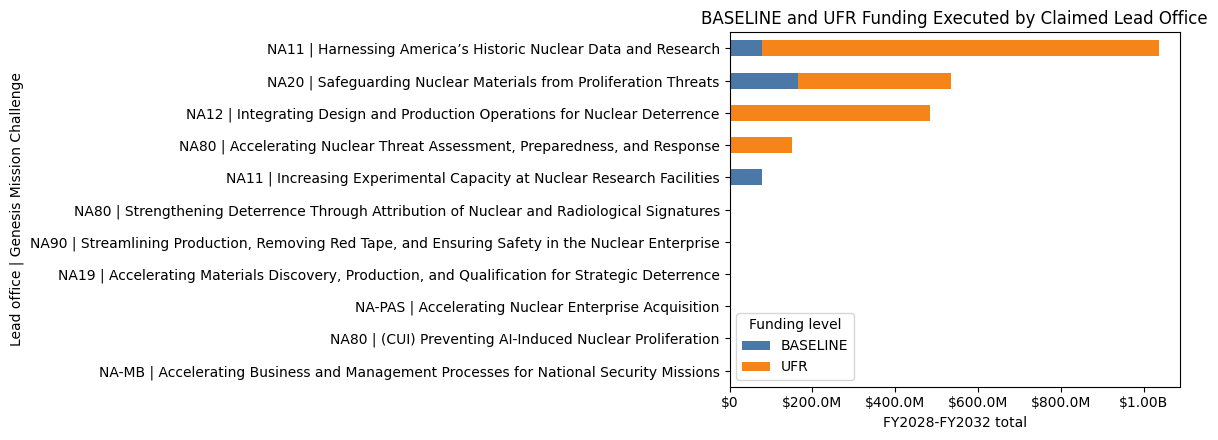

### Lead office project-level evidence

,lead_program_office,challenge_name,funding_level,five_year_total_display,fy2028_display,fy2029_display,fy2030_display,fy2031_display,fy2032_display,wbs_name,wbs_code,source_row_number,confidence,review_flag,scope_description
4,NA11,Harnessing America’s Historic Nuclear Data and Research,BASELINE,$77.5M,$15.0M,$15.1M,$14.3M,$16.6M,$16.6M,Archiving & Support,OEB.001.003.041.001,19,high,False,"AI/ML implementation including, software and licenses to automatically index, catalog, extract metadata and search an increased number of digital repositories"
0,NA11,Harnessing America’s Historic Nuclear Data and Research,UFR,$346.6M,$64.0M,$66.6M,$69.2M,$72.0M,$74.9M,Artificial Intelligence for Nuclear Security (AI4NS),OEB.001.003.040.017,3,medium,True,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
2,NA11,Harnessing America’s Historic Nuclear Data and Research,UFR,$338.5M,$62.5M,$65.0M,$67.6M,$70.3M,$73.1M,Computational Systems & Software Environment,OEB.001.003.040.014,5,medium,True,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
5,NA11,Harnessing America’s Historic Nuclear Data and Research,UFR,$153.8M,$30.0M,$31.2M,$32.4M,$31.2M,$29.0M,Archiving & Support,OEB.001.003.041.001,21,high,False,"Expanded deployment of the Terrier tool suite across the design agencies to provide data conditioning, curation, and labeling for legacy weapons data."
1,NA11,Harnessing America’s Historic Nuclear Data and Research,UFR,$119.2M,$22.0M,$22.9M,$23.8M,$24.7M,$25.7M,Artificial Intelligence for Nuclear Security (AI4NS),OEB.001.003.040.017,4,medium,True,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
3,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$44.1M,$7.2M,$8.1M,$9.2M,$9.8M,$9.8M,Secondary Assessment Technologies,OEB.001.003.001.004,15,medium,False,"AI/ML work across multiple HED experiments: analysis and modeling of data, with the goal of developing more refined approaches"
8,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$2.0M,$1.0M,$1.0M,$0,$0,$0,"ICF Diagnostics & Instrumentation (formerly Diagnostics, Cryogenics & Experimental Support)",OEB.001.003.003.003,28,medium,True,Constraining Mix using radiochemistry on NIF
7,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$19.5M,$5.0M,$4.7M,$4.8M,$2.5M,$2.5M,Facility Operations (formerly also Target Production),OEB.001.003.003.005,24,high,False,"Capability Development, ICF Operations, Develop experimental capabilities and support for target metrology in Fusion Yield Platforms"
6,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$13.9M,$2.7M,$2.7M,$2.7M,$2.9M,$2.9M,Delivery Environments (formerly WSEAT),OEB.001.003.041.002,23,medium,True,Investigation of novel physics modeling pertinent to reentry systems and the associated validation and uncertainty quantification (VUQ)
9,NA12,Integrating Design and Production Operations for Nuclear Deterrence,UFR,$318.3M,$59.8M,$61.7M,$63.6M,$65.6M,$67.7M,Multi-Weapon Systems (formerly MTP),OEB.001.001.003.008,33,low,False,Critical Executable CE UFR: Genesis AI


In [6]:
positive_funding_rows = reviewed_classifications.loc[
    reviewed_classifications["funding_level"].astype(str).str.upper().isin(["BASELINE", "UFR"])
].copy()

lead_project_rows = positive_funding_rows.merge(
    lead_claims[["challenge_name", "lead_program_office", "validation_status", "execution_signal"]],
    left_on=["predicted_challenge", "normalized_funding_office"],
    right_on=["challenge_name", "lead_program_office"],
    how="inner",
)

for column in [*FY_COLUMNS, "five_year_total"]:
    if column in lead_project_rows.columns:
        lead_project_rows[column] = pd.to_numeric(lead_project_rows[column], errors="coerce").fillna(0.0)
        lead_project_rows[f"{column}_display"] = lead_project_rows[column].map(format_money)

if lead_project_rows.empty:
    lead_project_table = pd.DataFrame(
        columns=[
            "lead_program_office",
            "challenge_name",
            "funding_level",
            "five_year_total_display",
            "wbs_name",
            "wbs_code",
            "source_row_number",
            "confidence",
            "review_flag",
            "scope_description",
        ]
    )
    lead_project_funding = pd.DataFrame(
        columns=["lead_program_office", "challenge_name", "funding_level", "five_year_total"]
    )
else:
    lead_project_table = lead_project_rows[
        [
            "lead_program_office",
            "challenge_name",
            "funding_level",
            "five_year_total_display",
            "fy2028_display",
            "fy2029_display",
            "fy2030_display",
            "fy2031_display",
            "fy2032_display",
            "wbs_name",
            "wbs_code",
            "source_row_number",
            "confidence",
            "review_flag",
            "scope_description",
        ]
    ].sort_values(
        ["lead_program_office", "challenge_name", "funding_level", "five_year_total_display"],
        ascending=[True, True, True, False],
    )
    lead_project_funding = lead_project_rows.groupby(
        ["lead_program_office", "challenge_name", "funding_level"],
        as_index=False,
    ).agg(
        project_rows=("programming_record_id", "nunique"),
        wbs_count=("wbs_name", "nunique"),
        five_year_total=("five_year_total", "sum"),
    )

funding_amount_pivot = lead_project_funding.pivot_table(
    index=["lead_program_office", "challenge_name"],
    columns="funding_level",
    values="five_year_total",
    aggfunc="sum",
    fill_value=0.0,
).reset_index()
for funding_level in ["BASELINE", "UFR"]:
    if funding_level not in funding_amount_pivot.columns:
        funding_amount_pivot[funding_level] = 0.0

funding_count_pivot = lead_project_funding.pivot_table(
    index=["lead_program_office", "challenge_name"],
    columns="funding_level",
    values="project_rows",
    aggfunc="sum",
    fill_value=0,
).reset_index()
funding_count_pivot = funding_count_pivot.rename(
    columns={"BASELINE": "baseline_project_rows", "UFR": "ufr_project_rows"}
)
for column in ["baseline_project_rows", "ufr_project_rows"]:
    if column not in funding_count_pivot.columns:
        funding_count_pivot[column] = 0

lead_execution_summary = lead_claims[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "evidence_row_count",
        "evidence_wbs_count",
        "review_flag_count",
    ]
].merge(
    funding_amount_pivot,
    on=["lead_program_office", "challenge_name"],
    how="left",
).merge(
    funding_count_pivot,
    on=["lead_program_office", "challenge_name"],
    how="left",
)
for column in ["BASELINE", "UFR", "baseline_project_rows", "ufr_project_rows"]:
    lead_execution_summary[column] = pd.to_numeric(
        lead_execution_summary[column], errors="coerce"
    ).fillna(0)
lead_execution_summary["lead_programmed_total"] = (
    lead_execution_summary["BASELINE"] + lead_execution_summary["UFR"]
)
lead_execution_summary["baseline_display"] = lead_execution_summary["BASELINE"].map(format_money)
lead_execution_summary["ufr_display"] = lead_execution_summary["UFR"].map(format_money)
lead_execution_summary["lead_programmed_total_display"] = lead_execution_summary[
    "lead_programmed_total"
].map(format_money)
lead_execution_summary_display = lead_execution_summary[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "baseline_display",
        "ufr_display",
        "lead_programmed_total_display",
        "baseline_project_rows",
        "ufr_project_rows",
        "evidence_wbs_count",
        "review_flag_count",
    ]
].sort_values(["validation_status", "lead_program_office", "challenge_name"])

display(Markdown("### Lead office BASELINE/UFR funding by claimed mission"))
display(lead_execution_summary_display)

bar_source = lead_execution_summary.copy()
bar_source["lead_mission"] = (
    bar_source["lead_program_office"] + " | " + bar_source["challenge_name"]
)
bar_plot = bar_source.set_index("lead_mission")[["BASELINE", "UFR"]]
bar_plot = bar_plot.loc[bar_plot.sum(axis=1).sort_values().index]
if bar_plot.sum(axis=1).gt(0).any():
    ax = bar_plot.plot(
        kind="barh",
        stacked=True,
        figsize=(12, max(4.5, 0.4 * len(bar_plot))),
        color=[FUNDING_LEVEL_COLORS["BASELINE"], FUNDING_LEVEL_COLORS["UFR"]],
    )
    ax.set_title("BASELINE and UFR Funding Executed by Claimed Lead Office")
    ax.set_xlabel("FY2028-FY2032 total")
    ax.set_ylabel("Lead office | Genesis Mission Challenge")
    ax.xaxis.set_major_formatter(lambda value, _: format_money(value))
    ax.legend(title="Funding level")
    plt.tight_layout()
    plt.show()
else:
    display(Markdown("No BASELINE or UFR funding rows were found for lead office claims."))

display(Markdown("### Lead office project-level evidence"))
display(lead_project_table)


In [7]:
claim_matrix = office_claim_validation.pivot_table(
    index="claimed_office",
    columns="challenge_name",
    values="validation_status",
    aggfunc=lambda values: "; ".join(sorted(set(values))),
    fill_value="",
)
display(claim_matrix)

challenge_name,(CUI) Preventing AI-Induced Nuclear Proliferation,Accelerating Business and Management Processes for National Security Missions,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",Accelerating Nuclear Enterprise Acquisition,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",Harnessing America’s Historic Nuclear Data and Research,Increasing Experimental Capacity at Nuclear Research Facilities,Integrating Design and Production Operations for Nuclear Deterrence,Safeguarding Nuclear Materials from Proliferation Threats,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",Strengthening Deterrence Through Attribution of Nuclear and Radiological Signatures
claimed_office,,,,,,,,,,,
NA-MB,,unfunded,,,,,,,,,
NA-PAS,,,,unfunded,,,,,,,
NA11,,,validated,,,validated,validated,validated,,unfunded,
NA12,,,,,,unfunded,,needs_review,,unfunded,
NA19,,,unfunded,,,,,unfunded,,unfunded,
NA20,unfunded,,,,unfunded,unfunded,unfunded,,needs_review,,validated
NA70,,,,,,,,,,unfunded,
NA80,unfunded,,,,validated,unfunded,unfunded,,unfunded,,unfunded
NA90,,,,,,,,,,unfunded,


In [8]:
challenge_display = challenge_coverage.copy()
challenge_display["five_year_total_display"] = challenge_display["five_year_total"].map(format_money)
display(
    challenge_display[
        [
            "challenge_name",
            "claim_count",
            "validated",
            "needs_review",
            "unfunded",
            "evidence_row_count",
            "evidence_wbs_count",
            "five_year_total_display",
            "claimed_offices",
            "actual_funding_offices",
        ]
    ]
)

,challenge_name,claim_count,validated,needs_review,unfunded,evidence_row_count,evidence_wbs_count,five_year_total_display,claimed_offices,actual_funding_offices
0,(CUI) Preventing AI-Induced Nuclear Proliferation,2,0,0,2,0,0,$0,NA20; NA80,NaN
1,Accelerating Business and Management Processes for National Security Missions,2,1,0,1,6,6,$727.1M,NA-MB; NAIM,NA11; NA70; NA90; NAIM
2,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",2,1,0,1,7,5,$206.2M,NA11; NA19,NA11
3,Accelerating Nuclear Enterprise Acquisition,2,1,0,1,3,3,$846.1M,NA-PAS; NAIM,NA11; NA20; NAIM
4,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",2,1,0,1,8,8,$382.5M,NA20; NA80,NA11; NA80; NAESH; NAIM
5,Harnessing America’s Historic Nuclear Data and Research,5,1,0,4,7,5,$1.22B,NA11; NA12; NA20; NA80; NAIM,NA11; NA90; NAESH
6,Increasing Experimental Capacity at Nuclear Research Facilities,3,1,0,2,8,7,$247.2M,NA11; NA20; NA80,NA11; NA90
7,Integrating Design and Production Operations for Nuclear Deterrence,3,1,1,1,9,8,$654.2M,NA11; NA12; NA19,NA11; NA12; NA30
8,Safeguarding Nuclear Materials from Proliferation Threats,3,0,1,2,4,3,$535.0M,NA20; NA80; NAIM,NA20
9,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",6,0,0,6,1,1,$5.5M,NA11; NA12; NA19; NA70; NA90; NAESH,NA30


In [9]:
unclaimed_evidence = office_challenge_evidence.loc[~office_challenge_evidence["is_claimed"].astype(bool)].copy()
unclaimed_evidence["five_year_total_display"] = unclaimed_evidence["five_year_total"].map(format_money)
unclaimed_evidence = unclaimed_evidence.sort_values("five_year_total", ascending=False)
display(
    unclaimed_evidence[
        [
            "challenge_name",
            "normalized_funding_office",
            "evidence_row_count",
            "evidence_wbs_count",
            "five_year_total_display",
            "evidence_wbs_names",
        ]
    ]
)


,challenge_name,normalized_funding_office,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
1,Accelerating Business and Management Processes for National Security Missions,NA11,1,1,$216.8M,Artificial Intelligence for Nuclear Security (AI4NS)
6,Accelerating Nuclear Enterprise Acquisition,NA11,1,1,$192.0M,Artificial Intelligence for Nuclear Security (AI4NS)
13,Harnessing America’s Historic Nuclear Data and Research,NA90,1,1,$183.7M,"32-D-XXX New Central Computing Facility, Y-12"
16,Increasing Experimental Capacity at Nuclear Research Facilities,NA90,4,3,$167.7M,LANL - 23-D-517 Electrical Power Capacity Upgrade; Maintenance at Working Facilities; Other Project Costs
9,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",NA11,2,2,$112.5M,HED & Ignition Science for Stockpile Applications (formerly Ignition); Primary Assessment Technologies
10,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",NAESH,1,1,$75.0M,"Safety Analytics, Forecasting, Evaluation and Reporting (SAFER)"
11,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",NAIM,1,1,$45.0M,Artificial Intelligence - Program Work
7,Accelerating Nuclear Enterprise Acquisition,NA20,1,1,$17.5M,Civil Nuclear Cooperation & Engagement
19,Integrating Design and Production Operations for Nuclear Deterrence,NA30,1,1,$16.2M,Reactor Systems & Component Technology
3,Accelerating Business and Management Processes for National Security Missions,NA90,1,1,$15.2M,Operations of Facilties


In [10]:
office_summary = office_claim_validation.copy()
office_summary["five_year_total_display"] = office_summary["five_year_total"].map(format_money)
for office, office_rows in office_summary.groupby("claimed_office"):
    display(Markdown(f"## {office}"))
    display(
        office_rows[
            [
                "challenge_name",
                "claim_role",
                "validation_status",
                "evidence_row_count",
                "evidence_wbs_count",
                "five_year_total_display",
                "evidence_wbs_names",
            ]
        ].sort_values(["validation_status", "challenge_name"])
    )

## NA-MB

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
4,Accelerating Business and Management Processes for National Security Missions,lead,unfunded,0,0,$0,NaN


## NA-PAS

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
6,Accelerating Nuclear Enterprise Acquisition,lead,unfunded,0,0,$0,NaN


## NA11

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
17,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",partner,unfunded,0,0,$0,NaN
25,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",partner,validated,7,5,$206.2M,Advanced Certification & Qualification (formerly Advanced Certification); Advanced Manufacturing Development; Aging & Lifetimes (formerly Enhanced Surveillance); Delivery Environments (formerly WSEAT); Dynamic Materi...
28,Harnessing America’s Historic Nuclear Data and Research,lead,validated,5,3,$1.04B,Archiving & Support; Artificial Intelligence for Nuclear Security (AI4NS); Computational Systems & Software Environment
29,Increasing Experimental Capacity at Nuclear Research Facilities,lead,validated,4,4,$79.5M,"Delivery Environments (formerly WSEAT); Facility Operations (formerly also Target Production); ICF Diagnostics & Instrumentation (formerly Diagnostics, Cryogenics & Experimental Support); Secondary Assessment Technol..."
30,Integrating Design and Production Operations for Nuclear Deterrence,partner,validated,6,6,$154.7M,Dynamic Materials Properties; Facility Operations (formerly also Target Production); HED & Ignition Science for Stockpile Applications (formerly Ignition); Hydrodynamic & Subcritical Execution Support (formerly RDC&S...


... (12 outputs left out)

## NAESH

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
22,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",partner,unfunded,0,0,$0,NaN


## NAIM

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
11,Harnessing America’s Historic Nuclear Data and Research,partner,unfunded,0,0,$0,NaN
16,Safeguarding Nuclear Materials from Proliferation Threats,partner,unfunded,0,0,$0,NaN
24,Accelerating Business and Management Processes for National Security Missions,partner,validated,3,3,$485.0M,Artificial Intelligence - Program Work; Enterprise Operations; Mission Contract Tasks
26,Accelerating Nuclear Enterprise Acquisition,partner,validated,1,1,$636.6M,Artificial Intelligence - Program Work


In [11]:
reviewed_display = reviewed_classifications.copy()
reviewed_display["five_year_total_display"] = reviewed_display["five_year_total"].map(format_money)
display(
    reviewed_display[
        [
            "programming_record_id",
            "source_row_number",
            "wbs_name",
            "source_sub_office",
            "normalized_funding_office",
            "funding_level",
            "predicted_challenge",
            "confidence",
            "review_flag",
            "five_year_total_display",
            "scope_description",
        ]
    ].sort_values(["predicted_challenge", "normalized_funding_office", "wbs_name"])
)

,programming_record_id,source_row_number,wbs_name,source_sub_office,normalized_funding_office,funding_level,predicted_challenge,confidence,review_flag,five_year_total_display,scope_description
19,programming_record:programming_data_csv:20,20,Archiving & Support,NA11,NA11,DECREMENT,Accelerating Business and Management Processes for National Security Missions,medium,False,-$10.4M,"Decrement would necessitate a workforce reduction of approximately 17 full-time employees in FY28 across our laboratories, plants, and sites. Given that A&S activities are heavily concentrated in personnel and AI/ML ..."
1,programming_record:programming_data_csv:2,2,Artificial Intelligence for Nuclear Security (AI4NS),NA11,NA11,BASELINE,Accelerating Business and Management Processes for National Security Missions,medium,True,$216.8M,"Participation in the Genesis Platforms that apply AI solutions to accelerating mission problems, increasing enterprise efficiency, or increasing scientific/engineering insight."
42,programming_record:programming_data_csv:43,43,Security Program Operations & Planning,NA70,NA70,BASELINE,Accelerating Business and Management Processes for National Security Missions,high,True,$10.0M,CSTART - Use of AI to enhance capabilities within the S&S program is growing and has potential to yeild valuable improvemements in addressing gaps and effeciciencies. This activity will be coordianted with the overal...
50,programming_record:programming_data_csv:51,51,Operations of Facilties,NA90,NA90,UFR,Accelerating Business and Management Processes for National Security Missions,medium,True,$15.2M,Telecommunication & AI Infrastructure Program Integration
58,programming_record:programming_data_csv:59,59,Artificial Intelligence - Program Work,NAIM,NAIM,BASELINE,Accelerating Business and Management Processes for National Security Missions,medium,False,$15.1M,Covers all expenses including labor and equipment associated with Artificial Intelligence investments.
...,...,...,...,...,...,...,...,...,...,...,...
39,programming_record:programming_data_csv:40,40,Export Control,NA24,NA20,UFR,Safeguarding Nuclear Materials from Proliferation Threats,high,True,$8.0M,Export control IT systems upgrade to increase efficiency and accelerate statutory technical reviews of export licenses for U.S. nuclear and dual-use commodities.
35,programming_record:programming_data_csv:36,36,PD,NA22,NA20,BASELINE,Safeguarding Nuclear Materials from Proliferation Threats,medium,True,$165.0M,AI PROGRAM WORK
36,programming_record:programming_data_csv:37,37,PD,NA22,NA20,UFR,Safeguarding Nuclear Materials from Proliferation Threats,high,True,$342.0M,"This UFR will accelerate the application of AI to challenging proliferation detection scenarios, including through deployment and maturation of DNN R&D's Alexandria Data Management System; the development, prototypin..."
41,programming_record:programming_data_csv:42,42,"Laboratory Facility Regulation, Compliance, & Protection",NA30,NA30,BASELINE,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",high,False,$5.5M,"Activities to ensure Naval Reactors program operations meet or exceed applicable federal, state, and local standards and requirements."


In [12]:
from programming_ontology._dashboard_report import write_classification_dashboard_html

html = write_classification_dashboard_html(
    paths,
    reviewed_classifications=reviewed_classifications,
    office_claim_validation=office_claim_validation,
    challenge_coverage=challenge_coverage,
    office_challenge_evidence=office_challenge_evidence,
)
display(Markdown(f"Exported executive dashboard HTML to `{paths.CLASSIFICATION_DASHBOARD_HTML_PATH}`."))


Exported executive dashboard HTML to `C:\Users\Cameron.Webster\Python\ProgrammingOntology\outputs\reports\classification_dashboard.html`.